[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/05-ml-forecasting.ipynb)

# Machine-Learning Forecasts: Lag and Calendar Features

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Build lag, rolling and calendar features that respect the forecast horizon.</li>
<li>Explain what a model uses with permutation importance and feature-group ablations.</li>
<li>Spot and quantify leakage from a too-short lag or a window that includes the target.</li>
<li>Compare direct and recursive forecasting strategies.</li>
</ul>
</div>

**Prerequisites:** Pages 1 to 4 of this track; scikit-learn basics. **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

A very different way to forecast: forget the time-series machinery and treat it as an **ordinary supervised-learning table**. Each row is one target hour; the columns are things we can know *at the moment we forecast* (the hour of day, the weekday, what demand was yesterday and a week ago, recent averages); the target is that hour's demand. Then any regressor you already know (gradient boosting, linear models) can be used.

This is how most forecasting is done in industry today, because it scales to thousands of series and accepts any extra column (weather, prices, holidays). It is also the setting in which **leakage** is easiest to commit and hardest to spot. So this page spends as much time on what you must *not* use as on what you can.

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
H = 24
test_origins = fc.rolling_origins(y.index, first_origin="2023-03-18")
train = y[:"2023-03-17"]
four_week = fc.backtest(y, lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4), origins=test_origins, horizon=H)
print("baseline to beat, 4-week average:", {k: round(v, 3) for k, v in fc.score(four_week, train).items()})

baseline to beat, 4-week average: {'MAE': 276.629, 'RMSE': 380.879, 'sMAPE': 0.071, 'MASE': 0.801}


## 1. What may a feature use?

The forecast is made at **midnight** for the 24 hours that follow, so the newest value we hold is from 23:00 of the day before. For a target hour *t* that means a feature can use a value from time $t - k$ only if it already exists at the origin. For the *last* hour of the day (23:00 tomorrow), the newest available value is 24 hours older. So the rule for a day-ahead forecast is simple: **every lag must be at least 24 hours**.

`fc.make_features(y, min_lag=24, lags=..., windows=...)` builds calendar, lag and rolling-mean columns and *refuses* a lag shorter than the forecast horizon:

In [3]:
try:
    fc.make_features(y, min_lag=24, lags=(1, 24))
except ValueError as err:
    print("ValueError:", err)

X = fc.make_features(y, min_lag=24, lags=(24, 48, 168, 336, 504), windows=(24, 168))
X["same_hour_4w"] = pd.concat([y.shift(168 * k) for k in (1, 2, 3, 4)], axis=1).mean(axis=1)   # a baseline as a feature
print("features:", list(X.columns))
X.assign(target=y).loc["2023-02-01 08:00":"2023-02-01 10:00"].round(0)

ValueError: Lags must be >= min_lag=24, otherwise the feature is unknown at forecast time.
features: ['hour', 'dayofweek', 'lag_24', 'lag_48', 'lag_168', 'lag_336', 'lag_504', 'mean_24', 'mean_168', 'same_hour_4w']


,hour,dayofweek,lag_24,lag_48,lag_168,lag_336,lag_504,mean_24,mean_168,same_hour_4w,target
hour,,,,,,,,,,,
2023-02-01 08:00:00,8,2,"5,489.00","4,488.00","5,183.00","5,294.00","5,099.00","3,574.00","4,309.00","4,991.00","5,334.00"
2023-02-01 09:00:00,9,2,"5,339.00","4,529.00","5,277.00","5,226.00","5,052.00","3,608.00","4,309.00","5,070.00","5,452.00"
2023-02-01 10:00:00,10,2,"4,978.00","4,341.00","5,062.00","5,312.00","5,205.00","3,634.00","4,308.00","5,086.00","5,427.00"


Look at one row in the table: for 08:00 on 1 February, `lag_24` is demand at 08:00 on 31 January, `lag_168` the same hour a week earlier, `mean_24` the average of the 24 hours ending at 08:00 on 31 January (it is computed from the series **shifted by 24**, so it never touches the target hour, nor anything newer than a day before it), and `same_hour_4w` the four-week seasonal average, i.e. our best baseline offered to the model as one more column.

Training one model per forecast origin means **fitting on rows whose target lies before the origin**, then predicting the 24 rows after it. We reuse `fc.backtest`:

In [4]:
def gbm_forecaster(cols=None, weeks=None, **params):
    cols = list(X.columns) if cols is None else cols
    settings = dict(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0) | params
    def forecaster(hist, idx):
        rows = X.loc[X.index.isin(hist.index), cols]
        if weeks:
            rows = rows.iloc[-168 * weeks:]
        rows = rows.dropna()                                   # the first weeks have no lag_504 yet
        model = HistGradientBoostingRegressor(**settings).fit(rows, hist.loc[rows.index])
        return model.predict(X.loc[idx, cols])
    return forecaster

bt_gbm = fc.backtest(y, gbm_forecaster(), origins=test_origins, horizon=H)
pd.DataFrame({"4-week seasonal average": fc.score(four_week, train),
              "gradient boosting on lag + calendar features": fc.score(bt_gbm, train)}).T.style.format(
    {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
4-week seasonal average,277,381,7.1%,0.80
gradient boosting on lag + calendar features,328,437,9.0%,0.95


The boosted model is **worse than the baseline** (MAE about 330 against 277). That is a normal result and an instructive one, so let us find out why before blaming the method.

## 2. What did the model actually use?

**Permutation importance** shuffles one column at a time and measures how much the error rises: a big rise means the model leaned on that column. We fit on data up to 10 March and measure on the following week, so that the importance is judged on data the model has not seen.

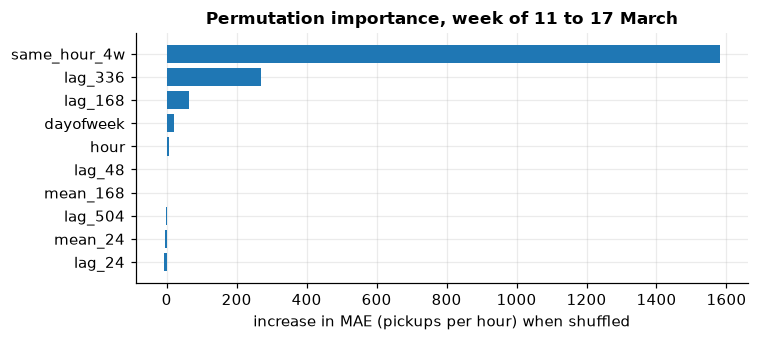

{'same_hour_4w': 1582.0, 'lag_336': 271.0, 'lag_168': 64.0}


In [5]:
fit_rows = X.loc[:"2023-03-10"].dropna()
check_rows = X.loc["2023-03-11":"2023-03-17"]
model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0).fit(fit_rows, y.loc[fit_rows.index])
imp = permutation_importance(model, check_rows, y.loc[check_rows.index], scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=0)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).round(0)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(importance.index[::-1], importance.to_numpy()[::-1], color="tab:blue")
ax.set(xlabel="increase in MAE (pickups per hour) when shuffled", title="Permutation importance, week of 11 to 17 March")
plt.tight_layout(); plt.show()
print(importance.head(3).to_dict())

**One column dominates: `same_hour_4w`**, the four-week seasonal average we handed the model (shuffling it raises the error by about 1,580 pickups an hour; the next column, `lag_336`, by about 270). The hour and the weekday barely register, not because they are irrelevant but because `same_hour_4w` already encodes both: **importance is shared out among redundant columns**, so read it as "what the model leans on", not "what matters in the world". In effect the model has been given the baseline's answer and mostly echoes it.

To test that reading, drop feature groups and compare the backtest error. If the lag features carry real extra information, removing them should hurt.

In [6]:
groups = {
    "all features": list(X.columns),
    "calendar only (hour, weekday)": ["hour", "dayofweek"],
    "calendar + same hour last week": ["hour", "dayofweek", "lag_168"],
    "lags only, no calendar": [c for c in X.columns if c not in ("hour", "dayofweek")],
    "everything except the 4-week average": [c for c in X.columns if c != "same_hour_4w"],
}
rows = {name: fc.score(fc.backtest(y, gbm_forecaster(cols), origins=test_origins, horizon=H), train) for name, cols in groups.items()}
ablation = pd.DataFrame(rows).T
ablation.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
all features,328,437,9.0%,0.95
"calendar only (hour, weekday)",324,444,10.8%,0.94
calendar + same hour last week,336,464,9.8%,0.97
"lags only, no calendar",341,452,9.3%,0.99
everything except the 4-week average,348,463,9.5%,1.01


All five versions land in the same band, roughly 320 to 350. **A model that sees only the hour and the weekday does as well as one with every lag.** So the lag columns add essentially nothing on this data; the tree is learning a seasonal profile, and learning it less efficiently than a plain average does, because each of the 168 weekday-hour slots has only about ten training examples and a tree splits them noisily.

Does the amount of history matter?

In [7]:
curve = {}
for weeks in (2, 3, 4, 6, 8, 10):
    curve[weeks] = fc.score(fc.backtest(y, gbm_forecaster(weeks=weeks), origins=test_origins, horizon=H), train)["MAE"]
curve = pd.Series(curve, name="MAE")
curve.index.name = "weeks of training history"
curve.round(0).astype(int).to_frame().T

weeks of training history,2,3,4,6,8,10
MAE,357,376,373,349,332,328


More history helps (about 375 with 3 to 4 weeks, about 330 with 8 to 10), though not smoothly. The learning curve is still falling at the longest window we can give it: with only 11 weeks in total, we cannot tell how far it would go. That is the real limitation here: **a flexible model needs data**. A seasonal average has one parameter per slot and needs almost none.

## 3. Leakage: how to look better than you are

Now the part of the page that matters most. Suppose we "improve" the features by adding yesterday's *last* hour, `lag_1`: the demand in the hour immediately before the target. In the training table it is perfectly legitimate: for every row, the value one hour earlier exists. But at the origin we do not know it, for any target hour after the first.

In [8]:
X_leaky = X.copy()
X_leaky["lag_1"] = y.shift(1)                              # NOT available at forecast time for steps 2 to 24
X_leaky["mean_24_including_now"] = y.rolling(24).mean()    # window includes the target hour itself

def leaky_forecaster(extra):
    cols = list(X.columns) + extra
    def forecaster(hist, idx):
        rows = X_leaky.loc[X_leaky.index.isin(hist.index), cols].dropna()
        model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0).fit(rows, hist.loc[rows.index])
        return model.predict(X_leaky.loc[idx, cols])
    return forecaster

leak = {
    "honest (all legal features)": fc.score(bt_gbm, train),
    "+ lag_1 (the previous hour)": fc.score(fc.backtest(y, leaky_forecaster(["lag_1"]), origins=test_origins, horizon=H), train),
    "+ 24-hour mean that includes the target hour": fc.score(fc.backtest(y, leaky_forecaster(["mean_24_including_now"]), origins=test_origins, horizon=H), train),
}
leak = pd.DataFrame(leak).T
leak.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
honest (all legal features),328,437,9.0%,0.95
+ lag_1 (the previous hour),265,351,7.7%,0.77
+ 24-hour mean that includes the target hour,318,424,9.0%,0.92


The `lag_1` model looks about **20% better** than the honest model, and the model with a window that includes the target hour a few percent better. **Both numbers are fiction.** In production, when we need the 15:00 forecast at midnight, the 14:00 value does not exist yet; and a window including the target hour contains the answer. The backtest passes the leaky columns because the whole series is in memory, which is why the `make_features` guard and the "origin sees only the past" rule in `fc.backtest` exist.

Notice that the second leak is *subtle*: a 24-hour rolling mean seems harmless, and it improved the score only a little. Small, quiet leaks are the dangerous kind, because they do not look suspicious. The only defence is the question **"would this number exist at the moment of the forecast?"**, asked of every column.

<div class="admonition warning">
<p class="admonition-title">Two ways to leak in time series</p>
<p><b>Using the future directly</b> (a lag shorter than the horizon, a window that includes the target). <b>Using it indirectly</b> through preprocessing: scaling, imputing or selecting features with statistics computed over the whole series including the test period. Fit every transformation on the training window only, exactly as in the leakage section of the scikit-learn pipelines page.</p>
</div>

## 4. Direct versus recursive forecasting

The model above is **direct**: one model, trained with lags of at least 24, predicts any of the 24 hours. The alternative is **recursive**: train a one-step-ahead model (using `lag_1`, which is legal for a one-step forecast), predict the next hour, append the prediction to the history, and repeat 24 times, feeding predictions back in as if they were observations.

In [9]:
def recursive_forecaster(lags=(1, 2, 24, 168)):
    def forecaster(hist, idx):
        table = pd.DataFrame({"hour": hist.index.hour, "dayofweek": hist.index.dayofweek}, index=hist.index)
        for lag in lags:
            table[f"lag_{lag}"] = hist.shift(lag)
        table = table.dropna()
        model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0).fit(table, hist.loc[table.index])
        extended, out = hist.copy(), []
        for t in idx:
            row = {"hour": t.hour, "dayofweek": t.dayofweek} | {f"lag_{lag}": extended[t - pd.Timedelta(hours=lag)] for lag in lags}
            prediction = model.predict(pd.DataFrame([row]))[0]
            extended.loc[t] = prediction                       # the forecast becomes "history" for the next step
            out.append(prediction)
        return np.array(out)
    return forecaster

bt_rec = fc.backtest(y, recursive_forecaster(), origins=test_origins, horizon=H)
pd.DataFrame({"direct (lags >= 24)": fc.score(bt_gbm, train), "recursive (feeds its own predictions back)": fc.score(bt_rec, train)}).T.style.format(
    {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
direct (lags >= 24),328,437,9.0%,0.95
recursive (feeds its own predictions back),358,480,9.9%,1.04


The recursive version is **worse** (MAE about 360 against 330). Errors compound: each step's mistake becomes the next step's input. Recursive forecasting is attractive when the horizon is long and training one model per horizon is too expensive, and it is *the* standard in classical models (ARIMA does it internally). But for tree models with a moderate horizon, the direct approach is the safer default.

## The honest verdict

On this series, with 11 weeks of history, **no learned model has beaten the six-week seasonal average**. That is not a failure of the page; it is the finding. Machine-learning forecasts earn their keep when there are *many series* to learn from, *external drivers* (weather, promotions, holidays) or *long histories*. For one series with a strong, stable weekly shape, a seasonal average is hard to beat and costs nothing to run and explain.

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| Spectacular backtest score | a feature that does not exist at forecast time (short lag, window including the target) | `make_features` guard; ask "would I have this at the origin?" for each column |
| Rolling mean looks harmless but leaks | window ends at the target hour | compute windows on the *shifted* series |
| Model does no better than hour and weekday alone | the lag features add nothing, the tree learns a profile | ablate feature groups before believing a feature helps |
| Tree model loses to a simple average | too few rows per seasonal slot | more history or more series; or use the average |
| Recursive forecast worse than direct | error compounding | train direct models, or accept it for long horizons |
| Scaling or imputing on the whole series | test statistics leak into training | fit transformers on the training window only |

## Check yourself

<details class="question">
<summary>1. You want a 48-hour-ahead forecast issued at midnight. What is the smallest lag you may use, and why?</summary>

**48 hours.** The newest value available at the origin is from 23:00 the previous day; for the target hour 47 hours later (23:00 on the second day) a lag of *k* hours reaches back to a time that is still in the future of the origin unless *k* ≥ 48. In general the minimum lag equals the horizon (the number of steps ahead of the last observed value), which is what `min_lag` encodes.

</details>

<details class="question">
<summary>2. A teammate adds a feature <code>mean_7d</code> = <code>y.rolling('7D').mean()</code> and the score improves by 5%. Is it safe?</summary>

Not as written. A rolling window ending **at** each row includes the target value itself (and the hours between the origin and the target, which are unknown). It must be computed on a shifted series, `y.shift(24).rolling('7D').mean()`, so that the row for time *t* only uses data from at least 24 hours earlier. Then re-run the backtest: if the improvement shrinks or disappears, it was leakage.

</details>

<details class="question">
<summary>3. The calendar-only model scores about the same as the model with ten features. Should you keep the ten features?</summary>

No: keep the simplest model that performs equally well. More features mean more data to maintain, more ways to leak, and more things to break in production, with no measured gain. Revisit when the evidence changes (more history, a new driver such as weather), not before.

</details>

## Exercises

<details class="question">
<summary>Predict the <em>residual</em> of the four-week average instead of demand itself: <code>target = y - same_hour_4w</code>, then add the baseline back. Is boosting from the baseline better than boosting from scratch?</summary>

```python
def residual_forecaster(hist, idx):
    rows = X.loc[X.index.isin(hist.index)].dropna()
    model = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_depth=3, random_state=0)
    model.fit(rows, hist.loc[rows.index] - rows["same_hour_4w"])
    return model.predict(X.loc[idx]) + X.loc[idx, "same_hour_4w"]
print(fc.score(fc.backtest(y, residual_forecaster, origins=test_origins, horizon=24), train)["MAE"])
```

It scores about 321: better than boosting from scratch (about 328 to 330), and still clearly worse than the baseline it starts from (277). The correction the model learns is mostly noise, which makes the baseline worse rather than better.

</details>

<details class="question">
<summary>Train the gradient-boosting model with the absolute-error loss (<code>loss='absolute_error'</code>), which matches the MAE metric. Does matching the loss to the metric help?</summary>

```python
print(fc.score(fc.backtest(y, gbm_forecaster(loss="absolute_error"), origins=test_origins, horizon=24), train)["MAE"])
```

It does not here: MAE is about 341, worse than the squared-error model's 328. Matching the loss to the metric is a good principle in general, but with so few rows per pattern the more robust but less efficient L1 fit has no room to help. Test it rather than assume.

</details>

<details class="question">
<summary>Add a feature for the <em>daily total of yesterday</em> (sum of the 24 hours of the previous day, known at midnight). Is it legal? Does it help?</summary>

```python
daily_before = y.resample("D").sum().shift(1)                       # each day gets the previous day's total
X["yesterday_total"] = daily_before.reindex(y.index, method="ffill")
print(fc.score(fc.backtest(y, gbm_forecaster(), origins=test_origins, horizon=24), train)["MAE"])
```

It is **legal**: at midnight the previous day's total is complete, and shifting by one day means the row for any hour of day *D* only sees days up to *D* - 1. (Check the shift before trusting it: using the *same* day's total would leak.) It does not help: the MAE moves from about 328 to about 336, slightly worse, consistent with the lag features adding nothing.

</details>

## Recap

- Forecasting becomes supervised learning once each row uses **only information available at the forecast origin**: lags and windows must respect the horizon (`min_lag`).
- Check what a model uses (**permutation importance**) and **ablate** feature groups; here the hour and weekday carried almost everything.
- Gradient boosting on one short series did **not** beat a seasonal average: flexible models need data, and the learning curve was still improving.
- **Leakage** can be spectacular (`lag_1`, about 20% better) or quiet (a window including the target hour, a few percent). Ask of every column: would it exist at the origin?
- **Direct** forecasting (lags at least the horizon) beat **recursive** forecasting here, where errors compound.

**Next:** *Backtesting: rolling origins and honest model comparison*.